## Dictionary Attack

Here, we demonstrate a simple example of a dictionary attack.

**Assumptions:**
- We have a general understanding of the target model and can therefore construct a local surrogate model 

**Goal & Dataset:**

We want to find an input that maximizes the models confidence for the class `TARGET_EMOTION`. As a dataset we load 28.7k grayscale images of human facial expressions from [FER2013](https://huggingface.co/datasets/SmolVEncoder/fer2013).

**General Idea:**
1. Load dataset & embed it locally using the surrogate model
2. Embed the target concepts using CLIP text encoder $\rightarrow$ in our case emotions  
3. Index dataset embeddings using FAISS to be able to quickly retrieve samples that are close to our target concepts
4. Use the k-th closest samples to the concept and query them using the API. Display one of the best found images.

In [ ]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132
%pip install faiss-cpu==1.15.1 numpy==2.5.4 open-clip-torch==3.3.0 datasets==5.1.0 matplotlib==3.11.2 tqdm==4.70.1

In [ ]:
import io
import base64
import faiss
import numpy as np
import open_clip
import requests
import torch

from datasets import load_dataset
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path

c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42

# Define target inference server URL
TARGET_SERVER_URL = "http://localhost:8000"
TARGET_EMOTION = "happiness"
MAX_REQUESTS = 50

# Surrogate model
MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"
WEIGHTS_PATH = Path("../weights/emotion_classifier_head.pth")
EMOTIONS = ["anger", "disgust", "fear", "happiness", "sadness", "surprise", "neutral"]
BATCH_SIZE = 128

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 2. Load & Preprocess dataset

In [3]:
df = load_dataset("SmolVEncoder/fer2013").shuffle(seed=SEED)
train_data = df["train"]

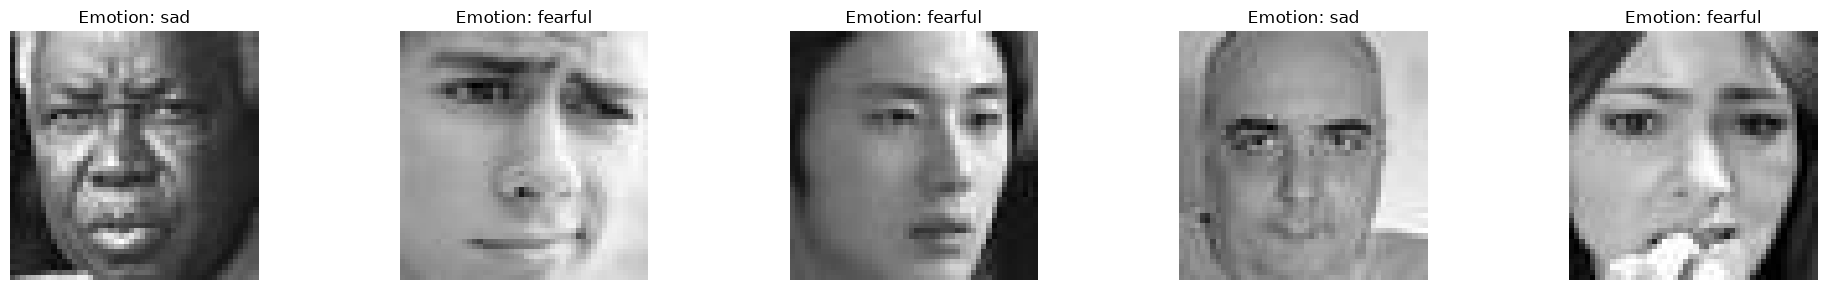

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3))

for i in range(5):
    sample = train_data[i]
    
    image = sample["image"]
    label = sample["label"]
    
    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Emotion: {label}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### 3. Embed dataset using surrogate model & Index it

In [5]:
### load the CLIP model and tokenizer
clip_backbone, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained=PRETRAINED)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)

dim = clip_backbone.visual.output_dim
emotion_head = torch.nn.Linear(dim, dim)
emotion_head.load_state_dict(torch.load(WEIGHTS_PATH, DEVICE))

clip_backbone = clip_backbone.to(DEVICE).eval()
emotion_head = emotion_head.to(DEVICE).eval()

### encode the target emotion concepts
emotion_features = [f'I am {emotion}' for emotion in EMOTIONS]  # dynamic target concept descriptions
with torch.inference_mode():
    emotion_text = clip_backbone.encode_text(tokenizer(emotion_features).to(DEVICE))
    emotion_text = emotion_text / emotion_text.norm(dim=-1, keepdim=True)

emotion_text = emotion_text.float().cpu().numpy()

In [6]:
### encode the dataset images
@torch.inference_mode()
def embed_images(images):
    batch = torch.stack([preprocess(img.convert("RGB")) for img in images]).to(DEVICE)
    feats = emotion_head(clip_backbone.encode_image(batch))
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats.float().cpu().numpy()

chunks = []
for start in tqdm(range(0, len(train_data), BATCH_SIZE), desc="Embedding"): # prefetching and copying to gpu would increase gpu util
    chunks.append(embed_images(train_data[start:start + BATCH_SIZE]["image"]))
embeddings = np.ascontiguousarray(np.concatenate(chunks), dtype="float32")

print(embeddings.shape)

Embedding: 100%|██████████| 225/225 [09:37<00:00,  2.57s/it]

(28709, 512)


In [7]:
### use a FAISS index to quickly find images close to the target emotion embeddings
index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)
print("Indexed vectors:", index.ntotal)

Indexed vectors: 28709


### 4. Conduct dictionary attack

In [8]:
session = requests.Session()


def parse_img_tobase64(image):
    buf = io.BytesIO()
    image.save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("utf-8")

def query_api(image):
    try:
        resp = session.post(
            TARGET_SERVER_URL + "/predict",
            json={"image": parse_img_tobase64(image), "classes": []},
            timeout=30,
        )
        resp.raise_for_status()
        return resp.json()["emotions"]
    except Exception as e:
        print(f"Request failed {e}")
        return None

def evaluate_candidates(indices, target, desc):
    results = []
    for idx in tqdm(indices, desc=desc):
        probs = query_api(train_data[int(idx)]["image"])
        if probs is not None:
            results.append({"idx": int(idx), "score": probs[target]})
    return sorted(results, key=lambda r: r["score"], reverse=True)

def dictionary_attack(target, budget=MAX_REQUESTS):
    t = EMOTIONS.index(target)

    query = emotion_text[t : t + 1]
    _, cand = index.search(query, budget)
    cand = cand[0]

    return evaluate_candidates(cand, target, desc=f"Attack ({target})")


In [10]:
attack = dictionary_attack(TARGET_EMOTION)

best = attack[0]
print(f"Dictionary attack best idx={best['idx']:6d}  score={best['score']:.6f}")

Attack (happiness): 100%|██████████| 50/50 [00:04<00:00, 11.60it/s]

Dictionary attack best idx= 21885  score=1.000000


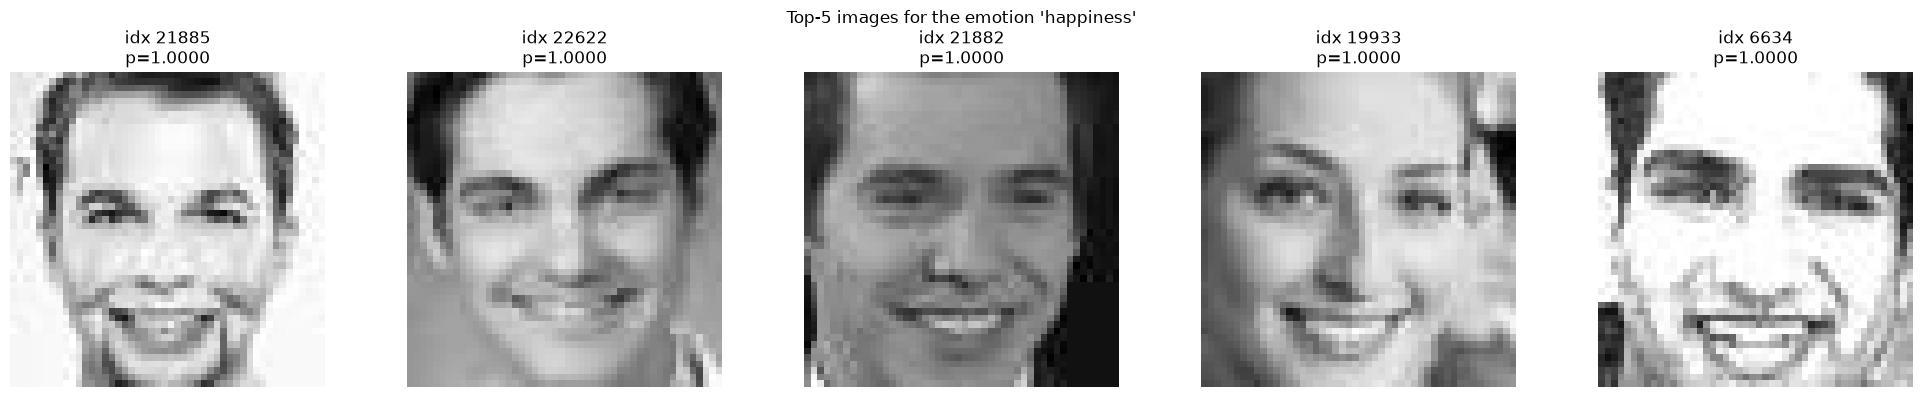

In [11]:
top = attack[:5]
fig, axes = plt.subplots(1, len(top), figsize=(4 * len(top), 4))

for ax, r in zip(axes, top):
    ax.imshow(train_data[r["idx"]]["image"], cmap="gray")
    ax.set_title(f"idx {r['idx']}\np={r['score']:.4f}")
    ax.axis("off")

plt.suptitle(f"Top-{len(top)} images for the emotion '{TARGET_EMOTION}'")
plt.tight_layout()
plt.show()

In [12]:
### quick sanity check over all emotions
results = {}
for emotion in EMOTIONS:
    results[emotion] = dictionary_attack(emotion)[0]

print(f"{'emotion':10s} | {'attack best score':>10s}")
print("-" * 30)
for emotion, res in results.items():
    print(f"{emotion:10s} | {res['score']:10.6f} ")

Attack (neutral): 100%|██████████| 50/50 [00:01<00:00, 28.97it/s]

emotion    | attack best score
------------------------------
anger      |   1.000000 
disgust    |   0.999999 
fear       |   1.000000 
happiness  |   1.000000 
sadness    |   1.000000 
surprise   |   1.000000 
neutral    |   1.000000 


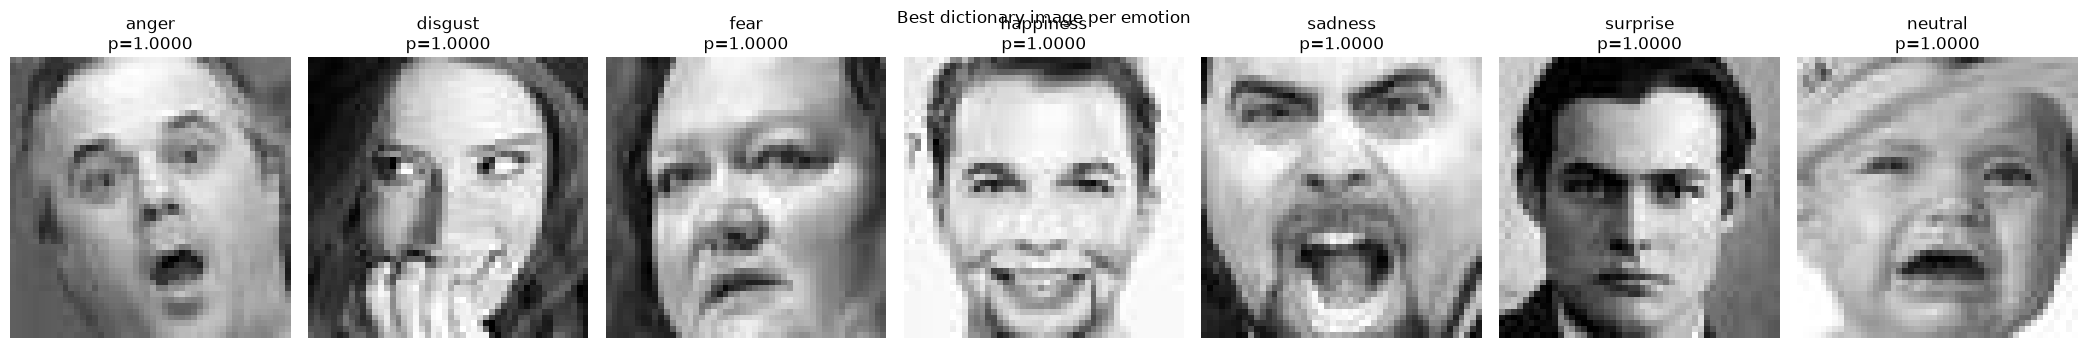

In [13]:
fig, axes = plt.subplots(1, len(EMOTIONS), figsize=(3 * len(EMOTIONS), 3.5))

for ax, (emotion, res) in zip(axes, results.items()):
    ax.imshow(train_data[res["idx"]]["image"], cmap="gray")
    ax.set_title(f"{emotion}\np={res['score']:.4f}")
    ax.axis("off")

plt.suptitle("Best dictionary image per emotion")
plt.tight_layout()
plt.show()